# Aula 06 — Veículo Autônomo em Tempo Real: por que a CPU não dá conta?

**Disciplina: Engenharia de Machine Learning — FIAP PosTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, por que a **CPU vira gargalo** em cargas pesadas de machine learning e como a **aceleração por hardware** (GPU, TPU, ASICs) reduz a latência e aumenta o throughput de um sistema que precisa funcionar em **tempo real**.

Usaremos como exemplo o caso de uma **fabricante de carros autônomos**. Ao final, você será capaz de:

1. Entender o problema de latência no processamento de sensores de um veículo autônomo.
2. Explicar de forma simples por que **GPUs superam CPUs** em ML e o que são **TPUs/ASICs**.
3. Medir na prática a latência média e o throughput (FPS) de um pipeline de percepção.
4. Comparar o processamento em **CPU** com o processamento em **GPU**.
5. Avaliar se o sistema atende à meta de segurança de **< 50 ms por frame** (idealmente ~30 ms).
6. Discutir tecnologias reais de aceleração (CUDA, cuDNN, TensorRT, XLA, multi-GPU) e seus trade-offs.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Geração de ruído e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib`. **Não requer GPU** (real), internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 06_aceleracao_hardware_gpu_tpu
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.14
numpy: 2.5.0
pandas: 3.0.3
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


## 1. Introdução: o veículo autônomo em tempo real

Imagine uma **fabricante de carros autônomos** desenvolvendo um sistema de **direção automática**. O veículo tem **múltiplas câmeras de alta resolução**, sensores **LIDAR** e **radares**, todos gerando dados não estruturados **em tempo real** (imagens e nuvens de pontos).

A cada instante, o carro precisa analisar esses dados e decidir se deve **virar, frear ou desviar**. Essa decisão tem que sair em **milissegundos** — num veículo em movimento, um atraso de poucos décimos de segundo pode ser a diferença entre **evitar um obstáculo** ou **provocar um acidente**.

### O protótipo inicial (só CPU)

No primeiro protótipo, apenas **CPUs tradicionais** processavam a visão computacional e a fusão de sensores. O problema apareceu rápido:

| Item | Valor aproximado |
|---|---|
| Hardware | CPU tradicional |
| Latência por frame | ~200 ms |
| Throughput | ~5 frames/s |
| Taxa das câmeras | ~30 frames/s |
| Meta de segurança | < 50 ms por frame (~30 ms ideal) |

### O problema

As câmeras geram **~30 quadros por segundo**, mas a CPU processa cada imagem em **~200 ms** — muito acima da meta de **33 ms** (equivalente a 30 FPS). Pior: ao **adicionar mais sensores** (câmeras laterais, traseiras e LIDAR simultâneos), o throughput não acompanha e **formam-se filas de imagens** esperando processamento. Com uma única CPU, o carro **não reage a tempo** aos eventos na estrada.

### O objetivo de negócio

O sistema precisa **reduzir a latência** para **< 50 ms por frame** (idealmente ~30 ms), **aumentar o throughput** para acompanhar todos os sensores e ser **confiável** o suficiente para operar em tempo real com segurança.

```
📷 Câmeras + 🛰️ LIDAR → [percepção / fusão de sensores] → [decisão: virar? frear? desviar?] → 🚗
```

> 🧩 A pergunta central da aula é: **a CPU consegue processar cada frame rápido o suficiente para o carro reagir a tempo? Se não, o que muda com a GPU?**

## 2. Conceitos principais

Antes do hands-on, alguns conceitos simples que amarram toda a aula. A ideia é entender **por que acelerar** — não decorar teoria.

### 🧠 Por que a CPU vira gargalo em ML?

A **CPU** tem poucos núcleos (ex.: 8 a 16) muito potentes, ótimos para tarefas **sequenciais** e variadas. Mas modelos de ML fazem **bilhões de multiplicações de matrizes** que poderiam rodar **em paralelo**. Com poucos núcleos, a CPU processa essas contas quase em fila — por isso a latência fica alta em cargas pesadas.

### 🎮 O que é GPU?

A **GPU (Graphics Processing Unit)** nasceu para gráficos, mas virou o **motor do deep learning**. Ela tem **milhares de núcleos** que executam operações **simultaneamente** (paralelismo massivo) e é otimizada para **multiplicações de matrizes** — exatamente o que as redes neurais mais fazem.

### ⚡ Por que GPUs superam CPUs em ML?

- **Paralelismo massivo:** milhares de operações rodando ao mesmo tempo.
- **Largura de banda de memória superior:** os dados fluem mais rápido para os núcleos.
- **Cálculo vetorial/matricial otimizado** (SIMD, **Tensor Cores** dedicados).
- **Escalabilidade:** várias GPUs trabalham juntas (NVLink, multi-GPU).

### 🔧 O que são TPUs e ASICs?

- **TPU (Tensor Processing Unit):** um **ASIC do Google** feito sob medida para IA. É projetado para **matrizes e tensores**, com throughput altíssimo (usando precisão reduzida) e **alta eficiência energética** (mais operações por watt).
- **ASIC (Application-Specific Integrated Circuit):** chip **dedicado a uma tarefa**. Outros exemplos: Huawei Ascend, Intel Habana, Cerebras (wafer-scale).

### 🧩 Como se programa um acelerador? (CUDA, cuDNN, TensorRT, XLA)

- **CUDA:** plataforma da NVIDIA para programar GPUs (C/C++/Python), com controle fino de kernels paralelos e memória.
- **cuDNN / TensorRT:** bibliotecas otimizadas sobre CUDA para acelerar deep learning e inferência.
- **XLA:** compilador que otimiza grafos do TensorFlow e do JAX, muito usado em **TPUs**.

> 🧮 **Paralelismo geral × massivo:** a CPU faz **poucas tarefas em paralelo** (bom para lógica variada); a GPU faz **milhares da mesma operação em paralelo** (bom para matrizes). Por isso a GPU brilha em ML.

## 3. Hands-on prático

Vamos **simular** o processamento dos frames de câmera em dois cenários e medir suas métricas. Em vez de rodar um modelo de visão real (que exigiria GPU e pesos treinados), simulamos o **tempo de processamento** de cada frame com `time.sleep()`. Assim o foco fica onde importa nesta aula: **medir latência e throughput** e ver o **ganho da GPU**.

- **Cenário A — CPU:** ~200 ms por frame (protótipo inicial).
- **Cenário B — GPU:** ~30 ms por frame (após instalar a GPU de alto desempenho).

Primeiro, os imports e a função de simulação que os dois cenários vão reutilizar.

In [2]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU real
# ------------------------------------------------------------------
import time                       # medir o tempo (latencia/throughput)
import numpy as np                # gerar o 'jitter' (ruido) e estatisticas
import pandas as pd               # montar a tabela comparativa
import matplotlib.pyplot as plt   # visualizar os resultados

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# Meta de seguranca: reagir em tempo real. A camera gera ~30 frames/s, entao
# o alvo e processar cada frame em <= ~33 ms (a meta de safety e < 50 ms).
META_FPS = 30
LATENCIA_ALVO_MS = 1000 / META_FPS   # ~33.3 ms por frame para acompanhar 30 FPS
LIMITE_SAFETY_MS = 50                # limite maximo de latencia por seguranca

print(f"Meta de tempo real: {META_FPS} FPS  (<= {LATENCIA_ALVO_MS:.1f} ms por frame)")
print(f"Limite de seguranca: < {LIMITE_SAFETY_MS} ms por frame")
print("Ambiente pronto.")

Meta de tempo real: 30 FPS  (<= 33.3 ms por frame)
Limite de seguranca: < 50 ms por frame
Ambiente pronto.


In [3]:
# ==================================================================
# FUNCAO DE SIMULACAO - o coracao do experimento
# ==================================================================
# OBJETIVO: imitar (simular) o computador de bordo processando frames das
# cameras, para conseguirmos MEDIR latencia e throughput (frames/segundo).
#
# POR QUE SIMULAR em vez de usar hardware real?
#   - Um modelo de visao real precisaria de GPU, pesos treinados, imagens
#     de verdade e bibliotecas pesadas. E nem todo aluno tem uma GPU.
#   - Nesta aula o foco NAO e a acuracia do modelo, e sim ENTENDER como o
#     hardware afeta latencia e throughput. Entao substituimos a inferencia
#     real por um time.sleep(): dormir X ms "finge" que o hardware levou X ms
#     para processar aquele frame. O relogio nao sabe a diferenca. :)
#
# IDEIA CENTRAL: se cada frame custa ~L milissegundos, quantos frames cabem
# em 1 segundo? Essa e a pergunta que a funcao responde, medindo o tempo de
# verdade com o cronometro do computador.


def simular_processamento(latencia_media_ms, n_frames=30, jitter_ms=5.0):
    """Processa N frames (simulados) e devolve as metricas de performance.

    Parametros
    ----------
    latencia_media_ms : tempo MEDIO que "o hardware" leva por frame (ms).
                        Ex.: 200 = CPU; 30 = GPU.
    n_frames          : quantos frames de camera processar em sequencia.
                        Pense nisso como "quantas imagens a camera mandou".
    jitter_ms         : o quanto o tempo de cada frame VARIA aleatoriamente.
                        No mundo real nenhum frame leva exatamente o mesmo
                        tempo (cache, sistema operacional, etc.). O jitter
                        adiciona essa variacao para ficar realista.

    Retorna
    -------
    dict com: n_frames, tempo_total_s, latencia_media_ms e fps.
    """
    # Lista onde vamos guardar a latencia REAL medida de cada frame (em ms).
    # No fim, a media dessa lista e a "latencia media por frame".
    latencias = []

    # ---- CRONOMETRO GERAL -------------------------------------------------
    # perf_counter() e um relogio de alta precisao (em segundos). Guardamos
    # o instante de INICIO do lote inteiro para, no final, saber quanto tempo
    # levou para processar TODOS os frames -> isso vira o throughput (FPS).
    inicio_total = time.perf_counter()

    # ---- LOOP: processa um frame de cada vez ------------------------------
    # Um pipeline simples analisa os frames em sequencia (um apos o outro).
    for _ in range(n_frames):
        # 1) Sortear quanto ESTE frame vai custar.
        #    np.random.normal(media, desvio) sorteia um numero em torno da
        #    latencia media. Ex.: media=200, jitter=8 -> normalmente entre
        #    ~184 e ~216 ms. Cada frame fica um pouco diferente (realismo).
        #    max(0.0, ...) e uma trava de seguranca: tempo nunca e negativo.
        atraso_ms = max(0.0, latencia_media_ms + np.random.normal(0, jitter_ms))

        # 2) Cronometrar o "processamento" deste unico frame.
        t0 = time.perf_counter()             # marca o inicio do frame
        time.sleep(atraso_ms / 1000.0)       # DORME atraso_ms (÷1000: ms -> s)
        t1 = time.perf_counter()             # marca o fim do frame
        # OBS: o time.sleep e o que "simula" o hardware trabalhando. Enquanto
        #      ele dorme, e como se a CPU/GPU estivesse calculando a resposta.

        # 3) Guardar a latencia REAL medida (t1 - t0), convertida de s para ms.
        latencias.append((t1 - t0) * 1000.0)

    # Instante de FIM do lote inteiro (todos os frames ja foram processados).
    fim_total = time.perf_counter()

    # ---- CALCULO DAS METRICAS --------------------------------------------
    # tempo_total_s: quanto tempo (em segundos) levou para processar tudo.
    tempo_total_s = fim_total - inicio_total

    # latencia_media_ms: media das latencias individuais -> "tempo tipico
    # por frame". E o numero que comparamos com a meta de ~33 ms / 50 ms.
    latencia_media = float(np.mean(latencias))

    # fps (frames por segundo): a metrica-chave de tempo real.
    # Formula: total de frames dividido pelo tempo total gasto.
    # Ex.: 30 frames em 6 s -> 5 FPS.  30 frames em 1 s -> 30 FPS.
    fps = n_frames / tempo_total_s

    # Devolvemos tudo num dicionario para as proximas celulas usarem/comparar.
    return {
        "n_frames": n_frames,
        "tempo_total_s": tempo_total_s,
        "latencia_media_ms": latencia_media,
        "fps": fps,
    }


print("Funcao 'simular_processamento' pronta para uso.")

Funcao 'simular_processamento' pronta para uso.


### Cenário A — CPU (protótipo inicial)

Simulamos o sistema **atual**: cada frame leva cerca de **200 ms** para ser processado na CPU. Vamos rodar 30 frames (como se fosse ~1 segundo de vídeo a 30 FPS) e medir o que realmente acontece.

In [4]:
# Cenario A - CPU: ~200 ms por frame
res_cpu = simular_processamento(latencia_media_ms=200, n_frames=30, jitter_ms=8)

print("=== Cenario A - CPU (prototipo inicial) ===")
print(f"Frames processados : {res_cpu['n_frames']}")
print(f"Tempo total        : {res_cpu['tempo_total_s']:.2f} s")
print(f"Latencia media     : {res_cpu['latencia_media_ms']:.1f} ms/frame")
print(f"FPS aproximado     : {res_cpu['fps']:.1f} FPS")

atende_cpu = res_cpu['latencia_media_ms'] < LIMITE_SAFETY_MS
print(f"Latencia < {LIMITE_SAFETY_MS} ms (safety)? -> {'SIM' if atende_cpu else 'NAO'}")

=== Cenario A - CPU (prototipo inicial) ===
Frames processados : 30
Tempo total        : 5.98 s
Latencia media     : 199.2 ms/frame
FPS aproximado     : 5.0 FPS
Latencia < 50 ms (safety)? -> NAO


Como esperado, com ~200 ms por frame o sistema fica **muito abaixo** dos 30 FPS (fica em torno de 5 FPS) e **muito acima** do limite de 50 ms. Para o carro, isso significa **reação lenta demais** — e, ao somar mais sensores, formam-se **filas de imagens** esperando processamento.

### Cenário B — GPU de alto desempenho

Agora simulamos o sistema **após instalar a GPU**: o paralelismo massivo derruba o tempo por frame para cerca de **30 ms**. Rodamos os **mesmos 30 frames** para comparar de forma justa.

In [5]:
# Cenario B - GPU: ~30 ms por frame
res_gpu = simular_processamento(latencia_media_ms=30, n_frames=30, jitter_ms=4)

print("=== Cenario B - GPU de alto desempenho ===")
print(f"Frames processados : {res_gpu['n_frames']}")
print(f"Tempo total        : {res_gpu['tempo_total_s']:.2f} s")
print(f"Latencia media     : {res_gpu['latencia_media_ms']:.1f} ms/frame")
print(f"FPS aproximado     : {res_gpu['fps']:.1f} FPS")

atende_gpu = res_gpu['latencia_media_ms'] < LIMITE_SAFETY_MS
print(f"Latencia < {LIMITE_SAFETY_MS} ms (safety)? -> {'SIM' if atende_gpu else 'NAO'}")

# Quanto mais rapido ficou o sistema com GPU em relacao a CPU?
ganho = res_cpu['latencia_media_ms'] / res_gpu['latencia_media_ms']
print(f"\nA GPU reduziu a latencia em ~{ganho:.1f}x em relacao a CPU.")

=== Cenario B - GPU de alto desempenho ===
Frames processados : 30
Tempo total        : 0.90 s
Latencia media     : 29.9 ms/frame
FPS aproximado     : 33.4 FPS
Latencia < 50 ms (safety)? -> SIM

A GPU reduziu a latencia em ~6.7x em relacao a CPU.


## 4. Comparação dos resultados

Vamos consolidar os dois cenários em uma **tabela** e, em seguida, em um **gráfico** para visualizar a diferença de latência e throughput.

In [6]:
# Tabela comparativa dos dois cenarios
tabela = pd.DataFrame([
    {
        "Cenario": "A - CPU (prototipo)",
        "Hardware": "CPU tradicional",
        "Latencia media (ms)": round(res_cpu["latencia_media_ms"], 1),
        "FPS aproximado": round(res_cpu["fps"], 1),
        "Atende < 50 ms?": "Sim" if res_cpu["latencia_media_ms"] < LIMITE_SAFETY_MS else "Nao",
    },
    {
        "Cenario": "B - GPU (solucao)",
        "Hardware": "GPU de alto desempenho",
        "Latencia media (ms)": round(res_gpu["latencia_media_ms"], 1),
        "FPS aproximado": round(res_gpu["fps"], 1),
        "Atende < 50 ms?": "Sim" if res_gpu["latencia_media_ms"] < LIMITE_SAFETY_MS else "Nao",
    },
])
tabela

,Cenario,Hardware,Latencia media (ms),FPS aproximado,Atende < 50 ms?
0,A - CPU (prototipo),CPU tradicional,199.2,5.0,Nao
1,B - GPU (solucao),GPU de alto desempenho,29.9,33.4,Sim


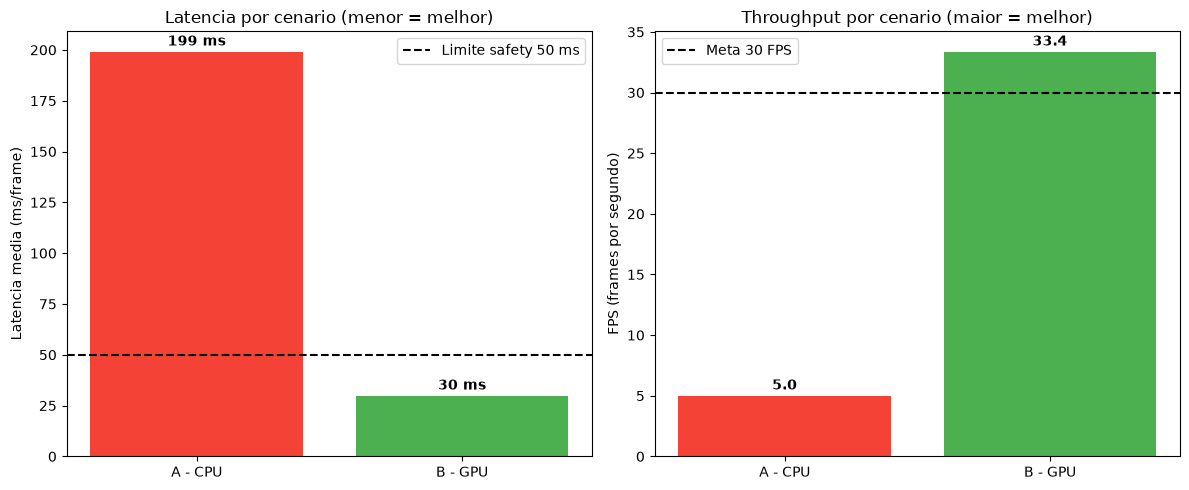

In [7]:
# Grafico comparativo: Latencia e FPS lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cenarios = ["A - CPU", "B - GPU"]
lat_vals = [res_cpu["latencia_media_ms"], res_gpu["latencia_media_ms"]]
fps_vals = [res_cpu["fps"], res_gpu["fps"]]
cores = ["#F44336", "#4CAF50"]  # vermelho = ruim, verde = bom

# Grafico 1: Latencia (quanto MENOR, melhor). Linha tracejada = limite de safety (50 ms).
axes[0].bar(cenarios, lat_vals, color=cores)
axes[0].axhline(LIMITE_SAFETY_MS, color="black", linestyle="--", label=f"Limite safety {LIMITE_SAFETY_MS} ms")
axes[0].set_ylabel("Latencia media (ms/frame)")
axes[0].set_title("Latencia por cenario (menor = melhor)")
axes[0].legend()
for i, v in enumerate(lat_vals):
    axes[0].text(i, v + 3, f"{v:.0f} ms", ha="center", fontweight="bold")

# Grafico 2: FPS (quanto MAIOR, melhor). Linha tracejada = meta de 30 FPS.
axes[1].bar(cenarios, fps_vals, color=cores)
axes[1].axhline(META_FPS, color="black", linestyle="--", label=f"Meta {META_FPS} FPS")
axes[1].set_ylabel("FPS (frames por segundo)")
axes[1].set_title("Throughput por cenario (maior = melhor)")
axes[1].legend()
for i, v in enumerate(fps_vals):
    axes[1].text(i, v + 0.5, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Discussão técnica: como acelerar de verdade?

Na simulação "apenas trocamos o número" da latência. No mundo real, essa redução vem de hardware e software especializados. Você **não precisa implementar todos** — basta entender como cada um ajudaria o veículo autônomo:

| Tecnologia | Ideia central | Como ajuda o carro autônomo |
|---|---|---|
| **GPU** | Paralelismo massivo (milhares de núcleos) | Processa vários sensores/frames ao mesmo tempo |
| **TPU** | ASIC focado em tensores/matrizes | Throughput altíssimo com alta eficiência energética |
| **ASICs sob medida** | Chip dedicado a IA (Ascend, Habana, Cerebras) | Máximo desempenho por watt para uma tarefa |
| **CUDA** | Programar a GPU da NVIDIA | Base para acelerar o software de percepção |
| **cuDNN** | Biblioteca de deep learning sobre CUDA | Camadas de rede neural mais rápidas |
| **TensorRT** | Otimizador de inferência da NVIDIA | Reduz latência do modelo em produção |
| **XLA** | Compilador de grafos (TF/JAX) | Otimiza execução, muito usado em TPUs |
| **Multi-GPU / NVLink** | Várias GPUs em paralelo | Escala para mais sensores e modelos maiores |

> 💡 Na prática, combina-se várias tecnologias. Um carro autônomo real costuma usar **GPU + TensorRT** (ou um ASIC dedicado) para atingir latência de poucos milissegundos processando **todos os sensores simultaneamente**.

### ⚖️ Trade-offs entre desempenho, custo e eficiência energética

Aceleradores trazem ganhos enormes, mas há um equilíbrio: GPUs e ASICs **custam mais**, **consomem energia** (importante num carro elétrico) e **adicionam complexidade** (drivers, refrigeração, software específico). O objetivo é escolher o hardware que atende à **meta de latência e segurança** com **custo e consumo aceitáveis**.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. A CPU atende ao requisito de < 50 ms por frame?**
❌ **Não.** Com ~200 ms por frame, a CPU entrega cerca de **5 FPS** — muito acima do limite de segurança e muito abaixo dos 30 FPS necessários. Ao somar sensores, ainda forma filas de processamento.

**2. A GPU atende ao requisito?**
✅ **Sim.** Com ~30 ms por frame, a GPU fica **dentro** do limite de segurança (< 50 ms) e alcança cerca de **30 FPS**, acompanhando o ritmo das câmeras.

**3. Qual foi o impacto da aceleração na latência e no throughput?**
A latência caiu de **~200 ms para ~30 ms** (redução de quase **7x**) e o throughput subiu para **>30 FPS por sensor**. Além disso, a GPU permite processar **vários sensores em paralelo** na mesma placa, sem formar filas.

**4. Por que isso é crítico para a segurança do veículo?**
Um carro em movimento precisa **reagir em milissegundos**. Com a GPU assumindo a carga pesada de ML, o sistema fica **responsivo e estável**, liberando a CPU para tarefas simples e reduzindo o risco de **sobrecarga/travamento** — o que é essencial para evitar acidentes.

**5. Quais trade-offs existem entre custo, desempenho e complexidade?**
Aceleradores custam mais, consomem energia e exigem software especializado (CUDA, TensorRT, XLA). O segredo é equilibrar **desempenho** (bater a meta de latência/safety), **custo** e **consumo**, escolhendo o hardware certo para o cenário.

### 📌 Principais aprendizados

1. A **CPU** é ótima para tarefas sequenciais, mas vira **gargalo** em cargas paralelas de ML.
2. A **GPU** usa **paralelismo massivo** para reduzir latência e aumentar throughput.
3. **TPUs e ASICs** são chips sob medida para IA, com alta eficiência por watt.
4. **CUDA, cuDNN, TensorRT e XLA** são o software que extrai o desempenho do hardware.
5. Medir é essencial: só comparando cenários sabemos se a solução atende ao requisito de segurança.

### 🚀 Próximos passos sugeridos

- Variar `n_frames` e a latência alvo e observar o efeito nos FPS.
- Simular **múltiplos sensores** (ex.: 4 câmeras + LIDAR) e ver a diferença entre processar em série (CPU) e em paralelo (GPU).
- Explorar, em um próximo módulo, inferência real com GPU usando TensorRT ou ONNX Runtime.

---

*Material da Aula 06 — Engenharia de Machine Learning — FIAP PosTech.*